In [4]:
%pip install -r ../requirements.txt

  Using cached numpy-2.5.5-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached pandas-3.1.1-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (16 kB)
  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2

In [5]:
import os
from datetime import datetime
import numpy as np
import pandas as pd

# 1. Semente fixa para reprodutibilidade
SEED = 42
np.random.seed(SEED)

# 2. Cria as pastas padrão do projeto
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# 3. Fonte oficial da base Telco Customer Churn (IBM)
url_telco = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
data_acesso = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

df_raw = pd.read_csv(url_telco)

# 4. Salva cópia
raw_path = "data/raw/Telco-Customer-Churn.csv"
df_raw.to_csv(raw_path, index=False)

print("Fonte:", url_telco)
print("Data/hora de acesso:", data_acesso)
print("Tamanho original (linhas, colunas):", df_raw.shape)

Fonte: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Data/hora de acesso: 2026-11-25 03:15:48
Tamanho original (linhas, colunas): (7043, 21)


In [6]:
df = df_raw.copy()

# 1. Verifica quantos espaços em branco (ou vazios) existem em TotalCharges antes de converter
espacos_total_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()
print("Valores em branco em TotalCharges antes da conversão:", espacos_total_charges)

# 2. Converte TotalCharges para numérico; textos inválidos/vazios viram NaN (ausentes)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")

# 3. Remove customerID (identificador único sem poder preditivo)
df = df.drop(columns=["customerID"])

# 4. Converte o alvo Churn de texto ("Yes"/"No") para binário numérico (1/0)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# 5. Padroniza nomes de colunas para snake_case (minúsculas e sem espaços)
df.columns = [
    col.strip().replace(" ", "_").lower()
    for col in df.columns
]

# 6. Verifica duplicatas exatas e quantidade de ausentes por coluna
duplicatas = df.duplicated().sum()
ausentes = df.isna().sum()

print("Linhas duplicadas exatas:", duplicatas)
print("\nValores ausentes por coluna após conversão:")
print(ausentes[ausentes > 0])
print("\nNovo formato (linhas, colunas):", df.shape)

Valores em branco em TotalCharges antes da conversão: 11
Linhas duplicadas exatas: 22

Valores ausentes por coluna após conversão:
totalcharges    11
dtype: int64

Novo formato (linhas, colunas): (7043, 20)


In [7]:
processed_path = "data/processed/telco_churn_etl.csv"
df.to_csv(processed_path, index=False)

# Significados e transformações aplicadas em cada coluna
descricoes = {
    "gender": ("Gênero do cliente (Male / Female)", "categoria", "Nomes padronizados para snake_case"),
    "seniorcitizen": ("Indica se o cliente é idoso (0 = não, 1 = sim)", "indicador (0/1)", "Nome padronizado para snake_case"),
    "partner": ("Possui parceiro(a) (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "dependents": ("Possui dependentes (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "tenure": ("Tempo de permanência do cliente com a empresa", "meses", "Nome padronizado para snake_case"),
    "phoneservice": ("Possui serviço de telefonia (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "multiplelines": ("Possui múltiplas linhas telefônicas", "categoria", "Nome padronizado para snake_case"),
    "internetservice": ("Tipo de serviço de internet (DSL, Fiber optic, No)", "categoria", "Nome padronizado para snake_case"),
    "onlinesecurity": ("Possui segurança online", "categoria", "Nome padronizado para snake_case"),
    "onlinebackup": ("Possui backup online", "categoria", "Nome padronizado para snake_case"),
    "deviceprotection": ("Possui proteção de dispositivo", "categoria", "Nome padronizado para snake_case"),
    "techsupport": ("Possui suporte técnico", "categoria", "Nome padronizado para snake_case"),
    "streamingtv": ("Possui streaming de TV", "categoria", "Nome padronizado para snake_case"),
    "streamingmovies": ("Possui streaming de filmes", "categoria", "Nome padronizado para snake_case"),
    "contract": ("Tipo de contrato (Month-to-month, One year, Two year)", "categoria", "Nome padronizado para snake_case"),
    "paperlessbilling": ("Utiliza fatura digital sem papel (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "paymentmethod": ("Forma de pagamento", "categoria", "Nome padronizado para snake_case"),
    "monthlycharges": ("Valor cobrado mensalmente do cliente", "unidade monetária (USD)", "Nome padronizado para snake_case"),
    "totalcharges": ("Valor total cobrado acumulado do cliente", "unidade monetária (USD)", "Convertido para numérico; espaços em branco viraram NaN"),
    "churn": ("Alvo: cliente cancelou o serviço (1 = Yes, 0 = No)", "binário (0/1)", "Mapeado de No/Yes para 0/1 e padronizado para minúscula"),
}

dicionario_dados = pd.DataFrame([
    {
        "coluna": col,
        "tipo_pandas": str(df[col].dtype),
        "significado": descricoes[col][0],
        "unidade": descricoes[col][1],
        "transformacao_etl": descricoes[col][2],
    }
    for col in df.columns
])

dicionario_dados.to_csv("data/processed/dicionario_dados_telco.csv", index=False)
print("Arquivos salvos em data/processed/ com sucesso.")
display(dicionario_dados)

Arquivos salvos em data/processed/ com sucesso.


,coluna,tipo_pandas,significado,unidade,transformacao_etl
0,gender,str,Gênero do cliente (Male / Female),categoria,Nomes padronizados para snake_case
1,seniorcitizen,int64,"Indica se o cliente é idoso (0 = não, 1 = sim)",indicador (0/1),Nome padronizado para snake_case
2,partner,str,Possui parceiro(a) (Yes / No),categoria,Nome padronizado para snake_case
3,dependents,str,Possui dependentes (Yes / No),categoria,Nome padronizado para snake_case
4,tenure,int64,Tempo de permanência do cliente com a empresa,meses,Nome padronizado para snake_case
5,phoneservice,str,Possui serviço de telefonia (Yes / No),categoria,Nome padronizado para snake_case
6,multiplelines,str,Possui múltiplas linhas telefônicas,categoria,Nome padronizado para snake_case
7,internetservice,str,"Tipo de serviço de internet (DSL, Fiber optic,...",categoria,Nome padronizado para snake_case
8,onlinesecurity,str,Possui segurança online,categoria,Nome padronizado para snake_case
9,onlinebackup,str,Possui backup online,categoria,Nome padronizado para snake_case


In [8]:
import pandas as pd

# 1. Distribuição do alvo 'churn' (0 = Não cancelou, 1 = Cancelou)
contagem_churn = df["churn"].value_counts()
pct_churn = df["churn"].value_counts(normalize=True) * 100
print("Distribuição do alvo 'churn':")
print(pd.DataFrame({"quantidade": contagem_churn, "percentual_%": pct_churn.round(2)}))

# 2. Duplicatas após remover customerID
print("\nTotal de linhas envolvidas em duplicatas exatas:", df.duplicated(keep=False).sum())
print("Linhas duplicadas excedentes:", df.duplicated().sum())

# 3. Categorias redundantes em colunas dependentes de internet e telefone
print("\nCruzamento internetservice vs onlinesecurity:")
print(pd.crosstab(df["internetservice"], df["onlinesecurity"]))

print("\nCruzamento phoneservice vs multiplelines:")
print(pd.crosstab(df["phoneservice"], df["multiplelines"]))

Distribuição do alvo 'churn':
       quantidade  percentual_%
churn                          
0            5174         73.46
1            1869         26.54

Total de linhas envolvidas em duplicatas exatas: 42
Linhas duplicadas excedentes: 22

Cruzamento internetservice vs onlinesecurity:
onlinesecurity     No  No internet service   Yes
internetservice                                 
DSL              1241                    0  1180
Fiber optic      2257                    0   839
No                  0                 1526     0

Cruzamento phoneservice vs multiplelines:
multiplelines    No  No phone service   Yes
phoneservice                               
No                0               682     0
Yes            3390                 0  2971


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score

X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

# Cenário 1: removendo linhas com valores ausentes em totalcharges
mask_train_ok = X_train.notna().all(axis=1)
mask_test_ok = X_test.notna().all(axis=1)

pipe_drop = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

pipe_drop.fit(X_train[mask_train_ok], y_train[mask_train_ok])
prob_drop = pipe_drop.predict_proba(X_test[mask_test_ok])[:, 1]
pred_drop = pipe_drop.predict(X_test[mask_test_ok])

# Cenário 2: mantendo todas as linhas e imputando a mediana dentro do Pipeline
pipe_impute = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

pipe_impute.fit(X_train, y_train)
prob_impute = pipe_impute.predict_proba(X_test)[:, 1]
pred_impute = pipe_impute.predict(X_test)

print("Sem linhas com ausentes:")
print(f"  ROC-AUC: {roc_auc_score(y_test[mask_test_ok], prob_drop):.4f} | F1: {f1_score(y_test[mask_test_ok], pred_drop):.4f}")

print("Com imputação da mediana dentro do Pipeline:")
print(f"  ROC-AUC: {roc_auc_score(y_test, prob_impute):.4f} | F1: {f1_score(y_test, pred_impute):.4f}")

Sem linhas com ausentes:
  ROC-AUC: 0.8418 | F1: 0.6061
Com imputação da mediana dentro do Pipeline:
  ROC-AUC: 0.8419 | F1: 0.6040


/tmp/ipykernel_11599/2308506870.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [10]:
import pandas as pd

diario_qualidade = pd.DataFrame([
    {
        "base": "Telco Customer Churn",
        "problema": "TotalCharges lido como texto com 11 valores em branco",
        "evidencia": "Coluna importada como objeto/texto; 11 espaços em branco viraram NaN após pd.to_numeric",
        "decisao_tomada": "Converter para numérico no ETL e imputar pela mediana dentro do Pipeline após o split treino/teste",
        "impacto_medido": "ROC-AUC passou de 0.8418 (sem linhas ausentes) para 0.8419 (com imputação no Pipeline); F1 de 0.6061 para 0.6040, preservando todas as linhas sem vazamento",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Coluna customerID sem poder preditivo",
        "evidencia": "Identificador único por linha sem relação real com cancelamento (churn)",
        "decisao_tomada": "Remover customerID na etapa de ETL",
        "impacto_medido": "Reduziu de 21 para 20 colunas, evitando ruído de identificador único",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "22 linhas duplicadas excedentes após remover customerID",
        "evidencia": "df.duplicated().sum() igual a 22 (42 linhas envolvidas em duplicatas exatas nas demais colunas)",
        "decisao_tomada": "Documentar no diário de qualidade e alinhar remoção/avaliação com a equipe antes do treino final",
        "impacto_medido": "Evita super-representação de registros idênticos no ajuste dos modelos",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Desbalanceamento da classe alvo churn",
        "evidencia": "Classe 0 (não cancelou) com 5.174 linhas (73,46%) e classe 1 (cancelou) com 1.869 linhas (26,54%)",
        "decisao_tomada": "Usar divisão estratificada (stratify=y) e comparar estratégias de balanceamento na modelagem",
        "impacto_medido": "Evita avaliação distorcida por acurácia simples na classe minoritária",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Categorias redundantes em colunas de serviços",
        "evidencia": "Ex.: 'No internet service' (1.526 linhas em onlinesecurity quando internetservice é 'No') e 'No phone service' (682 linhas em multiplelines)",
        "decisao_tomada": "Registrar a redundância no diário e no dicionário de dados para orientar o pré-processamento",
        "impacto_medido": "Aumenta a clareza na interpretação das variáveis categóricas do modelo",
    },
])

diario_qualidade.to_csv("data/processed/diario_qualidade_telco.csv", index=False)
print("Diário de qualidade salvo em data/processed/diario_qualidade_telco.csv")
display(diario_qualidade)

Diário de qualidade salvo em data/processed/diario_qualidade_telco.csv


,base,problema,evidencia,decisao_tomada,impacto_medido
0,Telco Customer Churn,TotalCharges lido como texto com 11 valores em...,Coluna importada como objeto/texto; 11 espaços...,Converter para numérico no ETL e imputar pela ...,ROC-AUC passou de 0.8418 (sem linhas ausentes)...
1,Telco Customer Churn,Coluna customerID sem poder preditivo,Identificador único por linha sem relação real...,Remover customerID na etapa de ETL,"Reduziu de 21 para 20 colunas, evitando ruído ..."
2,Telco Customer Churn,22 linhas duplicadas excedentes após remover c...,df.duplicated().sum() igual a 22 (42 linhas en...,Documentar no diário de qualidade e alinhar re...,Evita super-representação de registros idêntic...
3,Telco Customer Churn,Desbalanceamento da classe alvo churn,"Classe 0 (não cancelou) com 5.174 linhas (73,4...",Usar divisão estratificada (stratify=y) e comp...,Evita avaliação distorcida por acurácia simple...
4,Telco Customer Churn,Categorias redundantes em colunas de serviços,Ex.: 'No internet service' (1.526 linhas em on...,Registrar a redundância no diário e no dicioná...,Aumenta a clareza na interpretação das variáve...


## Registro de Uso de IA — Etapa de ETL e Qualidade de Dados

* **Responsável:** Arthur Azevedo Costa de Paula (16457)
* **Ferramenta utilizada:** Gemini (Google).
* **Finalidade do apoio:** Estruturação das células de extração, limpeza e padronização (ETL), montagem do dicionário de dados e organização dos testes de diagnóstico e comparação antes/depois para o diário de qualidade da base *Telco Customer Churn*.
* **Critério e verificação:** Todo o código foi executado integralmente no Google Colab, com conferência manual dos caminhos gerados (`data/raw/` e `data/processed/`), das dimensões da base (`7.043` linhas e `20` colunas após remoção de `customerID`), dos valores ausentes em `totalcharges` (`11` ocorrências tratadas sem vazamento dentro do `Pipeline`) e das métricas de validação (`ROC-AUC` e `F1`).

## 6. Modelagem — Classificação de churn

**Pergunta de negócio:** quais clientes têm maior risco de cancelar o serviço, para que a equipe de retenção aja antes do cancelamento?

**Qual erro custa mais caro?**

* **Falso negativo (FN):** cliente que vai cancelar e o modelo não detecta. A empresa perde toda a receita futura do cliente.
* **Falso positivo (FP):** cliente fiel que recebe uma ação de retenção (ligação, desconto) sem precisar. O custo é o da ação.

Como perder um cliente custa bem mais que uma ação de retenção, o FN é o erro mais caro: queremos **recall alto** sem disparar alertas demais.

**Métrica escolhida para a busca de hiperparâmetros: PR-AUC (`average_precision`).**

* Ela mede o quanto o modelo ordena bem os clientes que cancelam acima dos que ficam, **sem depender do limiar 0,5**. O limiar será escolhido depois, com base no custo dos erros.
* Com a classe positiva minoritária (~26,5%), a PR-AUC é mais exigente que a ROC-AUC: o valor de um modelo aleatório é a proporção de positivos (~0,27), e não 0,5.
* Também registramos ROC-AUC, F1, recall, precisão, acurácia balanceada e acurácia em todos os folds, para a comparação e a análise posteriores.

**Regra desta seção:** o conjunto de teste é separado no início e **não é usado** aqui. Toda comparação é feita por validação cruzada no treino. A avaliação no teste fica para a etapa seguinte.

In [11]:
# Instala o imbalanced-learn caso o ambiente não tenha (o Colab normalmente já tem)
%pip install -q imbalanced-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import time
import warnings

import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             make_scorer, precision_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
np.random.seed(SEED)
os.makedirs("reports", exist_ok=True)

# Métrica que guia a busca de hiperparâmetros (ver justificativa acima)
METRICA_PRINCIPAL = "pr_auc"

# Todas as métricas registradas em cada fold
SCORING = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
}

# Mesmos 5 folds estratificados para TODOS os modelos -> scores pareados por fold,
# o que permite o teste de Wilcoxon na etapa de comparação estatística
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### 6.1 Divisão treino/teste estratificada

O teste (20%) é separado **antes de qualquer transformação que aprende com os dados** (imputação, padronização, codificação, SMOTE). As únicas transformações já aplicadas no ETL não dependem de estatísticas da base: conversão de tipo de `totalcharges`, remoção de `customerID`, mapeamento do alvo e padronização dos nomes.

`stratify=y` mantém a mesma proporção de churn nos dois conjuntos, e `random_state=SEED` torna a divisão reprodutível.

In [13]:
X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas")
print(pd.DataFrame({
    "treino_%": (y_train.value_counts(normalize=True) * 100).round(2),
    "teste_%": (y_test.value_counts(normalize=True) * 100).round(2),
}).rename_axis("churn"))

# Diário de qualidade: as 22 duplicatas são clientes diferentes (customerID distintos)
# com o mesmo perfil. Verificamos quantas linhas do teste têm uma "gêmea" exata no treino.
gemeas = X_test.merge(X_train.drop_duplicates(), how="inner", on=list(X.columns))
print(f"\nLinhas do teste com cópia exata no treino: {len(gemeas)} de {len(X_test)}")

Treino: 5634 linhas | Teste: 1409 linhas
       treino_%  teste_%
churn                   
0         73.46    73.46
1         26.54    26.54

Linhas do teste com cópia exata no treino: 13 de 1409


### 6.2 Pré-processamento com `Pipeline` e `ColumnTransformer`

| Grupo | Colunas | Transformação | Por quê |
|---|---|---|---|
| Numéricas contínuas | `tenure`, `monthlycharges`, `totalcharges` | Imputação pela mediana + `StandardScaler` | `totalcharges` tem 11 ausentes (diário de qualidade); regressão logística e SVM são sensíveis à escala |
| Binária numérica | `seniorcitizen` | Mantida como está (0/1) | Já está codificada |
| Categóricas | as 15 colunas de texto | `OneHotEncoder(drop="if_binary", handle_unknown="ignore")` | Modelos exigem entrada numérica; `drop="if_binary"` deixa uma coluna só para Yes/No (facilita ler as razões de chance) |

Tudo fica **dentro do pipeline**: a mediana, a média e o desvio da padronização e as categorias do one-hot são aprendidos só com os dados de treino de cada fold, sem vazar informação do fold de validação nem do teste.

In [14]:
num_cols = ["tenure", "monthlycharges", "totalcharges"]
bin_cols = ["seniorcitizen"]
cat_cols = X.select_dtypes(include="object").columns.tolist()

assert set(num_cols + bin_cols + cat_cols) == set(X.columns), "Alguma coluna ficou de fora"


def construir_preprocessador():
    # Retorna um ColumnTransformer novo (sem ajuste) a cada chamada
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                              sparse_output=False), cat_cols),
    ])


# Apenas para inspeção: ajustado somente no treino
prep_demo = construir_preprocessador().fit(X_train)
nomes_features = prep_demo.get_feature_names_out()
print(f"{len(cat_cols)} colunas categóricas, {len(num_cols) + len(bin_cols)} numéricas")
print(f"Após o pré-processamento: {len(nomes_features)} atributos")
print(list(nomes_features))

15 colunas categóricas, 4 numéricas
Após o pré-processamento: 40 atributos
['num__tenure', 'num__monthlycharges', 'num__totalcharges', 'bin__seniorcitizen', 'cat__gender_Male', 'cat__partner_Yes', 'cat__dependents_Yes', 'cat__phoneservice_Yes', 'cat__multiplelines_No', 'cat__multiplelines_No phone service', 'cat__multiplelines_Yes', 'cat__internetservice_DSL', 'cat__internetservice_Fiber optic', 'cat__internetservice_No', 'cat__onlinesecurity_No', 'cat__onlinesecurity_No internet service', 'cat__onlinesecurity_Yes', 'cat__onlinebackup_No', 'cat__onlinebackup_No internet service', 'cat__onlinebackup_Yes', 'cat__deviceprotection_No', 'cat__deviceprotection_No internet service', 'cat__deviceprotection_Yes', 'cat__techsupport_No', 'cat__techsupport_No internet service', 'cat__techsupport_Yes', 'cat__streamingtv_No', 'cat__streamingtv_No internet service', 'cat__streamingtv_Yes', 'cat__streamingmovies_No', 'cat__streamingmovies_No internet service', 'cat__streamingmovies_Yes', 'cat__contrac

/tmp/ipykernel_11599/1041536153.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


### 6.3 Baseline: `DummyClassifier` (classe majoritária)

O baseline sempre prevê "não cancela" (classe 0). Ele mostra o piso que qualquer modelo precisa superar e **por que a acurácia engana** numa base desbalanceada.

,média,desvio
pr_auc,0.2654,0.0001
roc_auc,0.5000,0.0000
f1,0.0000,0.0000
recall,0.0000,0.0000
precision,0.0000,0.0000
balanced_accuracy,0.5000,0.0000
accuracy,0.7346,0.0001


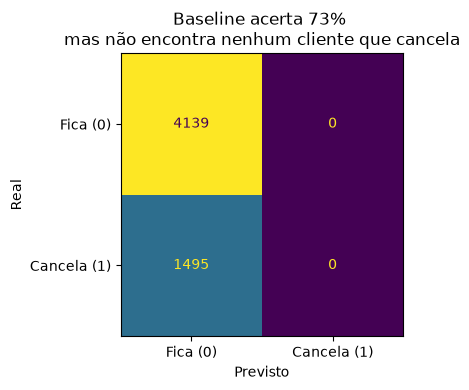

Acurácia do baseline: 73.46%
Recall do baseline:   0.00% (0 clientes sinalizados de 1495 que cancelaram)
PR-AUC do baseline:   0.2654 (≈ proporção de churn no treino: 0.2654)


In [15]:
baseline = Pipeline([
    ("prep", construir_preprocessador()),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

cv_baseline = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING)

resumo_baseline = pd.DataFrame({
    m: [cv_baseline[f"test_{m}"].mean(), cv_baseline[f"test_{m}"].std()]
    for m in SCORING
}, index=["média", "desvio"]).T.round(4)
display(resumo_baseline)

# Matriz de confusão com as previsões de validação cruzada (cada linha do treino
# é prevista pelo modelo que não a viu)
pred_baseline = cross_val_predict(baseline, X_train, y_train, cv=CV)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_train, pred_baseline),
                       display_labels=["Fica (0)", "Cancela (1)"]).plot(ax=ax, colorbar=False)
ax.set_title(f"Baseline acerta {resumo_baseline.loc['accuracy', 'média']:.0%} "
             "\nmas não encontra nenhum cliente que cancela")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

print(f"Acurácia do baseline: {resumo_baseline.loc['accuracy', 'média']:.2%}")
print(f"Recall do baseline:   {resumo_baseline.loc['recall', 'média']:.2%} "
      f"({(pred_baseline == 1).sum()} clientes sinalizados de {(y_train == 1).sum()} que cancelaram)")
print(f"PR-AUC do baseline:   {resumo_baseline.loc['pr_auc', 'média']:.4f} (≈ proporção de churn no treino: {y_train.mean():.4f})")

**Por que a acurácia engana:** o baseline tem cerca de 73% de acurácia sem aprender nada, apenas porque 73% dos clientes não cancelam. Ao mesmo tempo, o recall é 0: ele não encontra **nenhum** cliente que cancela, que é justamente o objetivo do negócio. A acurácia balanceada (0,5) e a PR-AUC (≈ proporção de positivos) expõem essa falha. Por isso a acurácia **não** é usada como métrica principal neste projeto.

### 6.4 Modelos, estratégias de desbalanceamento e busca de hiperparâmetros

Treinamos 3 modelos, cada um com 3 estratégias, todos com o **mesmo** pré-processamento e os **mesmos** 5 folds:

| Modelo | Por que entra |
|---|---|
| Regressão Logística | Modelo linear interpretável (razões de chance); referência forte em churn |
| SVM (kernel RBF) | Captura fronteiras não lineares; aceita `class_weight` (o KNN não aceita) |
| Random Forest | Ensemble de árvores; captura interações sem precisar de padronização |

| Estratégia | Como funciona |
|---|---|
| `sem_ajuste` | Treina com a proporção original (referência para medir o efeito das outras duas) |
| `class_weight` | `class_weight="balanced"`: erros na classe 1 pesam ~2,8× mais na função de perda (5.174 / 1.869) |
| `smote` | Gera exemplos sintéticos da classe 1 até igualar as classes. Fica **dentro** do `imblearn.pipeline.Pipeline`, depois do pré-processamento: só reamostra o fold de treino; o fold de validação e o teste nunca são reamostrados |

**Hiperparâmetros ajustados** (`GridSearchCV`, `refit` pela PR-AUC):

| Modelo | Hiperparâmetro | O que controla | Valores testados |
|---|---|---|---|
| Logística | `C` | Inverso da regularização L2: `C` pequeno encolhe mais os coeficientes (menos sobreajuste) | 0,01; 0,1; 1; 10 |
| SVM | `C` | Penalidade por erro de classificação: `C` alto gera fronteira mais ajustada ao treino | 0,1; 1; 10 |
| SVM | `gamma` | Alcance de cada exemplo no kernel RBF: `gamma` alto gera fronteira mais "recortada" | `scale`; 0,01 |
| Random Forest | `max_depth` | Profundidade máxima de cada árvore (limita a complexidade) | 8; 12; sem limite |
| Random Forest | `min_samples_leaf` | Mínimo de clientes por folha (suaviza as previsões) | 1; 5; 10 |
| SMOTE | `k_neighbors` | Quantos vizinhos da classe 1 são usados para criar cada exemplo sintético | 3; 5 |

Observações:

* O SVM não gera probabilidades por padrão. Na busca, a PR-AUC e a ROC-AUC usam o `decision_function`, que dá a mesma ordenação. O SVM candidato é calibrado depois com `CalibratedClassifierCV` (seção 6.6), para gerar as probabilidades usadas na escolha do limiar.
* O SMOTE interpola as colunas one-hot e cria valores fracionários (ex.: 0,4 em `contract_Two year`). É uma limitação conhecida; o `SMOTENC` trata categóricas de forma nativa e fica como alternativa.
* Tempo estimado no Colab: alguns minutos (o SVM é o mais lento).

In [16]:
def montar_pipeline(modelo, estrategia):
    # Monta pré-processamento + (SMOTE opcional) + modelo
    etapas = [("prep", construir_preprocessador())]
    if estrategia == "smote":
        etapas.append(("smote", SMOTE(random_state=SEED)))
    etapas.append(("clf", modelo))
    return ImbPipeline(etapas)


modelos = {
    "Regressão Logística": {
        "estimador": lambda cw: LogisticRegression(max_iter=2000, class_weight=cw),
        "grade": {"clf__C": [0.01, 0.1, 1, 10]},
    },
    "SVM (RBF)": {
        "estimador": lambda cw: SVC(kernel="rbf", class_weight=cw, random_state=SEED),
        "grade": {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01]},
    },
    "Random Forest": {
        "estimador": lambda cw: RandomForestClassifier(
            n_estimators=300, max_features="sqrt", class_weight=cw,
            random_state=SEED, n_jobs=-1),
        "grade": {"clf__max_depth": [8, 12, None], "clf__min_samples_leaf": [1, 5, 10]},
    },
}

estrategias = ["sem_ajuste", "class_weight", "smote"]

In [17]:
buscas = {}  # (modelo, estratégia) -> GridSearchCV ajustado

for nome_modelo, cfg in modelos.items():
    for estrategia in estrategias:
        cw = "balanced" if estrategia == "class_weight" else None
        grade = dict(cfg["grade"])
        if estrategia == "smote":
            grade["smote__k_neighbors"] = [3, 5]

        busca = GridSearchCV(
            montar_pipeline(cfg["estimador"](cw), estrategia),
            param_grid=grade,
            scoring=SCORING,
            refit=METRICA_PRINCIPAL,
            cv=CV,
            n_jobs=-1,
        )
        inicio = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=UserWarning)
            busca.fit(X_train, y_train)
        buscas[(nome_modelo, estrategia)] = busca
        print(f"{nome_modelo:<20} | {estrategia:<12} | "
              f"PR-AUC CV = {busca.best_score_:.4f} | {time.time() - inicio:5.1f}s | "
              f"{busca.best_params_}")

Regressão Logística  | sem_ajuste   | PR-AUC CV = 0.6615 |   5.5s | {'clf__C': 1}
Regressão Logística  | class_weight | PR-AUC CV = 0.6600 |   1.8s | {'clf__C': 1}
Regressão Logística  | smote        | PR-AUC CV = 0.6591 |   4.3s | {'clf__C': 1, 'smote__k_neighbors': 3}
SVM (RBF)            | sem_ajuste   | PR-AUC CV = 0.6543 |  29.6s | {'clf__C': 1, 'clf__gamma': 0.01}
SVM (RBF)            | class_weight | PR-AUC CV = 0.6582 |  28.2s | {'clf__C': 1, 'clf__gamma': 0.01}
SVM (RBF)            | smote        | PR-AUC CV = 0.6578 |  88.5s | {'clf__C': 0.1, 'clf__gamma': 0.01, 'smote__k_neighbors': 3}
Random Forest        | sem_ajuste   | PR-AUC CV = 0.6652 |  47.3s | {'clf__max_depth': 8, 'clf__min_samples_leaf': 10}
Random Forest        | class_weight | PR-AUC CV = 0.6640 |  49.2s | {'clf__max_depth': 8, 'clf__min_samples_leaf': 10}
Random Forest        | smote        | PR-AUC CV = 0.6543 | 121.3s | {'clf__max_depth': 8, 'clf__min_samples_leaf': 10, 'smote__k_neighbors': 3}


### 6.5 Resultados da validação cruzada

Para cada combinação, pegamos as métricas da **melhor configuração** de hiperparâmetros em cada um dos 5 folds. Como todos usam os mesmos folds, os scores são pareados e podem ser comparados com Wilcoxon na próxima etapa.

In [18]:
# Scores por fold de cada combinação (configuração escolhida pela busca)
linhas = []
for f in range(CV.get_n_splits()):
    linhas.append({"modelo": "Baseline (Dummy)", "estrategia": "-", "fold": f + 1,
                   **{m: cv_baseline[f"test_{m}"][f] for m in SCORING}})

for (nome_modelo, estrategia), busca in buscas.items():
    i = busca.best_index_
    for f in range(CV.get_n_splits()):
        linhas.append({"modelo": nome_modelo, "estrategia": estrategia, "fold": f + 1,
                       **{m: busca.cv_results_[f"split{f}_test_{m}"][i] for m in SCORING}})

scores_folds = pd.DataFrame(linhas)
scores_folds.to_csv("reports/cv_scores_por_fold_classificacao.csv", index=False)

# Resumo: média ± desvio por combinação, ordenado pela métrica principal
resumo_cv = (scores_folds.groupby(["modelo", "estrategia"])[list(SCORING)]
             .agg(["mean", "std"]))
resumo_fmt = pd.DataFrame({
    m: resumo_cv[(m, "mean")].map("{:.3f}".format) + " ± " + resumo_cv[(m, "std")].map("{:.3f}".format)
    for m in SCORING
})
resumo_fmt = resumo_fmt.loc[resumo_cv[(METRICA_PRINCIPAL, "mean")].sort_values(ascending=False).index]
display(resumo_fmt)

pr_auc        roc_auc             f1  \
modelo              estrategia                                                  
Random Forest       sem_ajuste    0.665 ± 0.021  0.848 ± 0.011  0.575 ± 0.017   
                    class_weight  0.664 ± 0.021  0.848 ± 0.011  0.631 ± 0.019   
Regressão Logística sem_ajuste    0.661 ± 0.022  0.846 ± 0.014  0.593 ± 0.034   
                    class_weight  0.660 ± 0.022  0.846 ± 0.014  0.628 ± 0.026   
                    smote         0.659 ± 0.024  0.845 ± 0.015  0.629 ± 0.023   
SVM (RBF)           class_weight  0.658 ± 0.020  0.842 ± 0.012  0.603 ± 0.006   
                    smote         0.658 ± 0.019  0.841 ± 0.012  0.624 ± 0.020   
                    sem_ajuste    0.654 ± 0.015  0.835 ± 0.016  0.561 ± 0.013   
Random Forest       smote         0.654 ± 0.016  0.845 ± 0.010  0.634 ± 0.017   
Baseline (Dummy)    -             0.265 ± 0.000  0.500 ± 0.000  0.000 ± 0.000   

                                         recall      precision  \
modelo              estrategia                                   
Random Forest       sem_ajuste    0.499 ± 0.018  0.679 ± 0.032   
                    class_weight  0.797 ± 0.024  0.523 ± 0.021   
Regressão Logística sem_ajuste    0.544 ± 0.046  0.653 ± 0.031   
                    class_weight  0.801 ± 0.042  0.517 ± 0.021   
                    smote         0.796 ± 0.047  0.520 ± 0.014   
SVM (RBF)           class_weight  0.829 ± 0.027  0.474 ± 0.010   
                    smote         0.805 ± 0.041  0.510 ± 0.015   
                    sem_ajuste    0.484 ± 0.012  0.669 ± 0.033   
Random Forest       smote         0.752 ± 0.032  0.548 ± 0.017   
Baseline (Dummy)    -             0.000 ± 0.000  0.000 ± 0.000   

                                 balanced_accuracy       accuracy  
modelo              estrategia                                     
Random Forest       sem_ajuste       0.707 ± 0.010  0.804 ± 0.010  
                    class_weight     0.767 ± 0.015  0.753 ± 0.016  
Regressão Logística sem_ajuste       0.720 ± 0.022  0.802 ± 0.014  
                    class_weight     0.765 ± 0.023  0.748 ± 0.017  
                    smote            0.766 ± 0.021  0.751 ± 0.011  
SVM (RBF)           class_weight     0.748 ± 0.006  0.710 ± 0.010  
                    smote            0.763 ± 0.018  0.743 ± 0.012  
                    sem_ajuste       0.699 ± 0.007  0.799 ± 0.009  
Random Forest       smote            0.764 ± 0.014  0.769 ± 0.011  
Baseline (Dummy)    -                0.500 ± 0.000  0.735 ± 0.000

pr_auc                        roc_auc             \
estrategia          class_weight sem_ajuste  smote class_weight sem_ajuste   
modelo                                                                       
Random Forest              0.664      0.665  0.654        0.848      0.848   
Regressão Logística        0.660      0.661  0.659        0.846      0.846   
SVM (RBF)                  0.658      0.654  0.658        0.842      0.835   

                                 recall                      precision  \
estrategia           smote class_weight sem_ajuste  smote class_weight   
modelo                                                                   
Random Forest        0.845        0.797      0.499  0.752        0.523   
Regressão Logística  0.845        0.801      0.544  0.796        0.517   
SVM (RBF)            0.841        0.829      0.484  0.805        0.474   

                                                f1                    
estrategia          sem_ajuste  smote class_weight sem_ajuste  smote  
modelo                                                                
Random Forest            0.679  0.548        0.631      0.575  0.634  
Regressão Logística      0.653  0.520        0.628      0.593  0.629  
SVM (RBF)                0.669  0.510        0.603      0.561  0.624

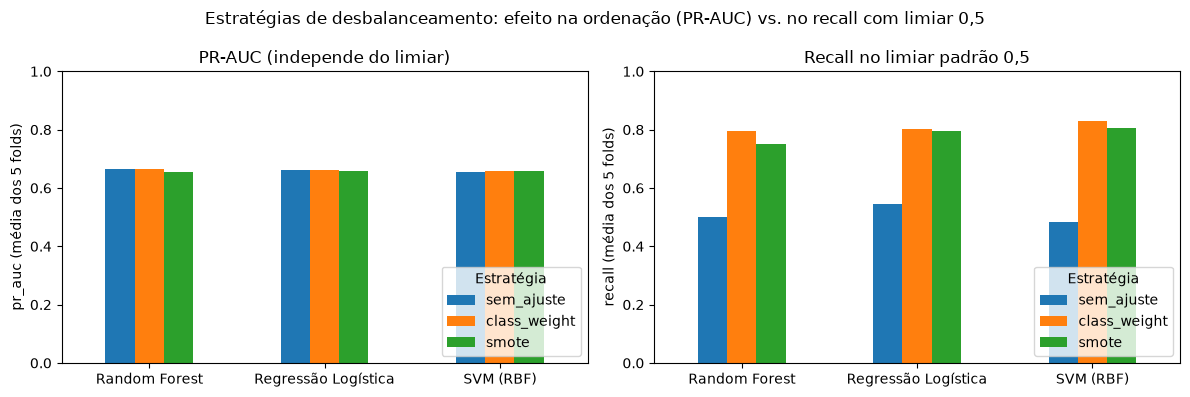

In [19]:
# Efeito das estratégias de desbalanceamento: média nos folds, por modelo
metricas_efeito = ["pr_auc", "roc_auc", "recall", "precision", "f1"]
efeito = (scores_folds[scores_folds["modelo"] != "Baseline (Dummy)"]
          .groupby(["modelo", "estrategia"])[metricas_efeito].mean()
          .unstack("estrategia").round(3))
display(efeito)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, metrica, titulo in [
    (axes[0], "pr_auc", "PR-AUC (independe do limiar)"),
    (axes[1], "recall", "Recall no limiar padrão 0,5"),
]:
    tabela = (scores_folds[scores_folds["modelo"] != "Baseline (Dummy)"]
              .pivot_table(index="modelo", columns="estrategia", values=metrica)
              [estrategias])
    tabela.plot.bar(ax=ax, rot=0)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel(f"{metrica} (média dos 5 folds)")
    ax.set_ylim(0, 1)
    ax.legend(title="Estratégia", loc="lower right")
fig.suptitle("Estratégias de desbalanceamento: efeito na ordenação (PR-AUC) vs. no recall com limiar 0,5")
plt.tight_layout()
plt.show()

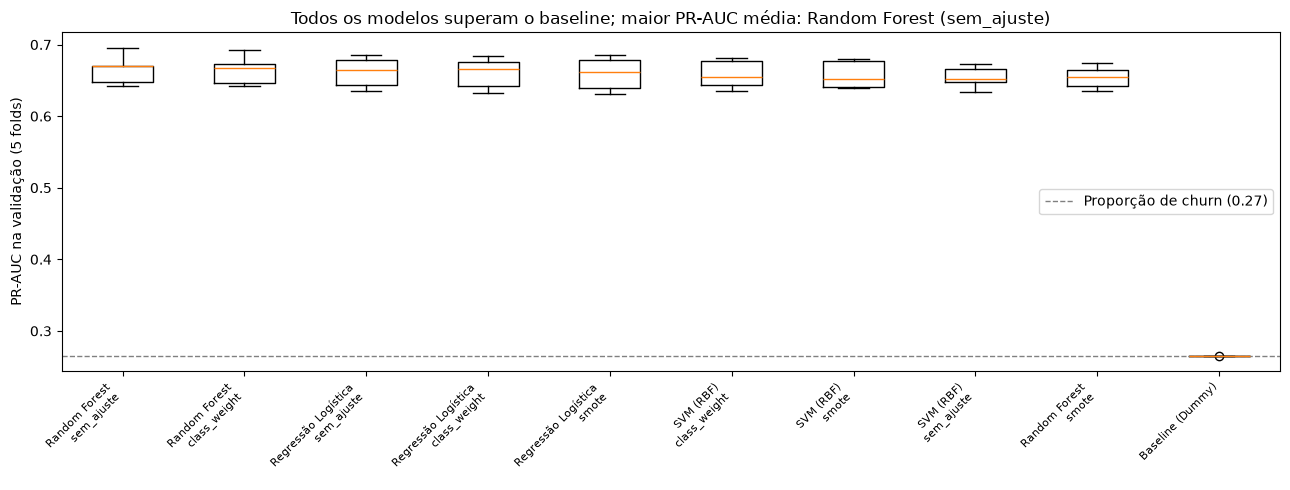

In [20]:
# Boxplot da métrica principal por fold, todos os modelos + baseline
ordem = (scores_folds.groupby(["modelo", "estrategia"])[METRICA_PRINCIPAL].mean()
         .sort_values(ascending=False).index)
rotulos = [f"{m}\n{e}" if e != "-" else m for m, e in ordem]
dados = [scores_folds[(scores_folds["modelo"] == m) & (scores_folds["estrategia"] == e)][METRICA_PRINCIPAL]
         for m, e in ordem]

melhor_m, melhor_e = ordem[0]
fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot(dados)
ax.set_xticks(range(1, len(rotulos) + 1))
ax.set_xticklabels(rotulos, rotation=45, ha="right", fontsize=8)
ax.axhline(y_train.mean(), ls="--", color="gray", lw=1, label=f"Proporção de churn ({y_train.mean():.2f})")
ax.set_ylabel("PR-AUC na validação (5 folds)")
ax.set_title(f"Todos os modelos superam o baseline; maior PR-AUC média: {melhor_m} ({melhor_e})")
ax.legend()
plt.tight_layout()
plt.show()

### 6.6 Melhores configurações e modelos candidatos

Para cada modelo, escolhemos **uma** estratégia de desbalanceamento com uma regra de parcimônia: se a diferença de PR-AUC entre a melhor estratégia e uma mais simples for menor que o desvio-padrão entre folds da melhor, a diferença é ruído e fica a mais simples (ordem de simplicidade: `sem_ajuste` < `class_weight` < `smote`).

O `GridSearchCV` já reajustou esses pipelines no treino inteiro (`refit`). O SVM ganha uma etapa de calibração (`CalibratedClassifierCV`, método sigmoide, com os mesmos 5 folds no treino) para produzir probabilidades. Os candidatos seguem para a próxima etapa: avaliação no teste, escolha do limiar e comparação estatística (McNemar / Wilcoxon, bootstrap).

**Por que as estratégias de desbalanceamento quase não mudam a PR-AUC?** `class_weight` e SMOTE deslocam as probabilidades para cima na classe 1, mas mudam pouco a **ordem** dos clientes por risco, que é o que a PR-AUC e a ROC-AUC medem. O efeito aparece no **recall com limiar 0,5** (gráfico da seção 6.5). Como o limiar será escolhido pelo custo do erro na próxima etapa, ajustar o limiar é uma terceira estratégia de desbalanceamento, e as três precisam ser comparadas no mesmo ponto de operação.

In [21]:
tabela_hiper = pd.DataFrame([
    {"modelo": m, "estrategia": e,
     "pr_auc_cv": round(b.best_score_, 4),
     "melhores_hiperparametros": b.best_params_}
    for (m, e), b in buscas.items()
]).sort_values(["modelo", "pr_auc_cv"], ascending=[True, False])
display(tabela_hiper)

# Escolha da estratégia por modelo, com regra de parcimônia
media_cv = scores_folds.groupby(["modelo", "estrategia"])[METRICA_PRINCIPAL].mean()
desvio_cv = scores_folds.groupby(["modelo", "estrategia"])[METRICA_PRINCIPAL].std()

modelos_candidatos = {}
for nome_modelo in modelos:
    melhor = max(estrategias, key=lambda e: media_cv[(nome_modelo, e)])
    tolerancia = desvio_cv[(nome_modelo, melhor)]
    # primeira estratégia (da mais simples para a mais complexa) dentro da tolerância
    escolhida = next(e for e in estrategias
                     if media_cv[(nome_modelo, melhor)] - media_cv[(nome_modelo, e)] <= tolerancia)

    pipe = buscas[(nome_modelo, escolhida)].best_estimator_
    if nome_modelo == "SVM (RBF)":
        # Calibra o SVM para gerar probabilidades (limiar, curvas PR/ROC); usa só o treino
        pipe = CalibratedClassifierCV(pipe, method="sigmoid", cv=CV).fit(X_train, y_train)

    modelos_candidatos[nome_modelo] = {"estrategia": escolhida, "pipeline": pipe,
                                       "pr_auc_cv": media_cv[(nome_modelo, escolhida)]}
    obs = "" if escolhida == melhor else (
        f"  [maior média: {melhor} = {media_cv[(nome_modelo, melhor)]:.4f}; "
        f"diferença < desvio entre folds ({tolerancia:.4f}), fica a mais simples]")
    print(f"{nome_modelo:<20} -> {escolhida:<12} "
          f"(PR-AUC CV = {media_cv[(nome_modelo, escolhida)]:.4f}){obs}")

ranking = sorted(modelos_candidatos, key=lambda m: modelos_candidatos[m]["pr_auc_cv"], reverse=True)
print(f"\nDois melhores na validação cruzada (para o teste pareado): {ranking[0]} e {ranking[1]}")

,modelo,estrategia,pr_auc_cv,melhores_hiperparametros
6,Random Forest,sem_ajuste,0.6652,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."
7,Random Forest,class_weight,0.6640,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."
8,Random Forest,smote,0.6543,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."
0,Regressão Logística,sem_ajuste,0.6615,{'clf__C': 1}
1,Regressão Logística,class_weight,0.6600,{'clf__C': 1}
2,Regressão Logística,smote,0.6591,"{'clf__C': 1, 'smote__k_neighbors': 3}"
4,SVM (RBF),class_weight,0.6582,"{'clf__C': 1, 'clf__gamma': 0.01}"
5,SVM (RBF),smote,0.6578,"{'clf__C': 0.1, 'clf__gamma': 0.01, 'smote__k_..."
3,SVM (RBF),sem_ajuste,0.6543,"{'clf__C': 1, 'clf__gamma': 0.01}"


Regressão Logística  -> sem_ajuste   (PR-AUC CV = 0.6615)
SVM (RBF)            -> sem_ajuste   (PR-AUC CV = 0.6543)  [maior média: class_weight = 0.6582; diferença < desvio entre folds (0.0204), fica a mais simples]
Random Forest        -> sem_ajuste   (PR-AUC CV = 0.6652)

Dois melhores na validação cruzada (para o teste pareado): Random Forest e Regressão Logística


**O que fica pronto para a próxima etapa:**

* `X_test`, `y_test`: conjunto de teste ainda intocado.
* `modelos_candidatos`: o melhor pipeline de cada modelo (com a sua estratégia de desbalanceamento), já ajustado no treino.
* `scores_folds` (e `reports/cv_scores_por_fold_classificacao.csv`): métricas por fold de todas as combinações e do baseline, para o teste de Wilcoxon.
* `ranking`: modelos ordenados pela PR-AUC média na validação cruzada.

> Leitura dos resultados (preencher após rodar no Colab): qual modelo e estratégia venceram, se a diferença para o segundo colocado é maior que o desvio entre folds, e o que o `class_weight` e o SMOTE mudaram na PR-AUC versus no recall com limiar 0,5.

## Registro de Uso de IA — Etapa de Modelagem (Classificação)

* *Responsável:* André Luís Gomes da Silva Filho - 855160
* *Ferramenta utilizada:* Claude (Anthropic), modelo Claude Opus 5.5.
* *Finalidade do apoio:* Usamos a IA como apoio na implementação da etapa de modelagem, a partir das tasks que já tínhamos definido no Trello. Ela ajudou a montar a primeira versão do código (split estratificado, pipeline de pré-processamento, baseline e busca de hiperparâmetros) e a discutir duas escolhas: usar PR-AUC como métrica da busca e comparar class_weight com SMOTE dentro do pipeline. Também usamos a IA para entender um erro de ambiente ao rodar o notebook localmente no VS Code (numpy e pandas não instalados no kernel).
* *O que ajustamos:* Revisamos o código antes de incorporar. Mantivemos a PR-AUC por fazer sentido para o nosso problema (o limiar será escolhido depois, pelo custo do erro). Aceitamos a regra de escolher a estratégia de balanceamento mais simples quando a diferença entre elas fica dentro da variação dos folds, porque na prática as três empataram.
* *Critério e verificação:* Rodamos o notebook do início ao fim no Colab (A1) e repetimos a execução para conferir os mesmos scores com a semente 42 (A2). Conferimos que o X_test não é usado em nenhum fit da seção (A4) e que os números citados no texto batem com as tabelas geradas (A6).